# 6. Практикум. Как исследовать разностную схему

Одна и та же схема переноса на одной сетке даёт точный ответ, на другой — ошибку второго порядка, а у края прямоугольного импульса рисует выброс выше единицы. Каждое из этих наблюдений можно предсказать по формуле шага.

В обоих примерах рассматривается периодический отрезок длины 1. Сетка состоит из $N$ точек $x_k=kh$, $h=1/N$. Начальные значения берутся из точного решения. На сетках с разным $N$ сравниваются профили в один и тот же физический момент $T=M\tau$. В качестве меры ошибки возьмём
$$
E_N=\left(\frac{1}{N}\sum_{k=0}^{N-1}\big|U_k^M-u(x_k,T)\big|^2\right)^{1/2}.
$$

## 1. Перенос. Как получить схему второго порядка?

Уравнение $u_t+c\,u_x=0$ при $c>0$ сдвигает начальный профиль $f(x)$ вправо. Точное решение равно $u(x,t)=f(x-ct)$. Посмотрим, как вычислить значение в одной точке за следующий шаг. Для гладкого профиля
$$
u(x,t+\tau)=u(x-c\tau,t)
=u(x,t)-c\tau u_x(x,t)+\frac{c^2\tau^2}{2}u_{xx}(x,t)+O(\tau^3).
$$

Заменим обе пространственные производные центральными разностями и обозначим через $C=c\tau/h$ число ячеек, которое проходит точное решение за шаг. Получится **схема Лакса–Вендроффа**
$$
U_k^{s+1}=U_k^s-\frac C2(U_{k+1}^s-U_{k-1}^s)
+\frac{C^2}{2}(U_{k+1}^s-2U_k^s+U_{k-1}^s).
$$

При $C=1$ коэффициенты при $U_k^s$ и $U_{k+1}^s$ обращаются в нуль. Остаётся $U_k^{s+1}=U_{k-1}^s$. За это время точное решение как раз проходит одну ячейку. Поэтому совпадает каждый отсчёт любого профиля, включая прямоугольник.

На рисунке $c=1$ и $T=1/4$. Гладкий профиль задан суммой $\cos(2\pi x)+\tfrac14\sin(4\pi x)$, а прямоугольный равен единице на $[1/4,1/2)$ и нулю снаружи. Нижний график показывает разность численного и точного решений в каждом узле.

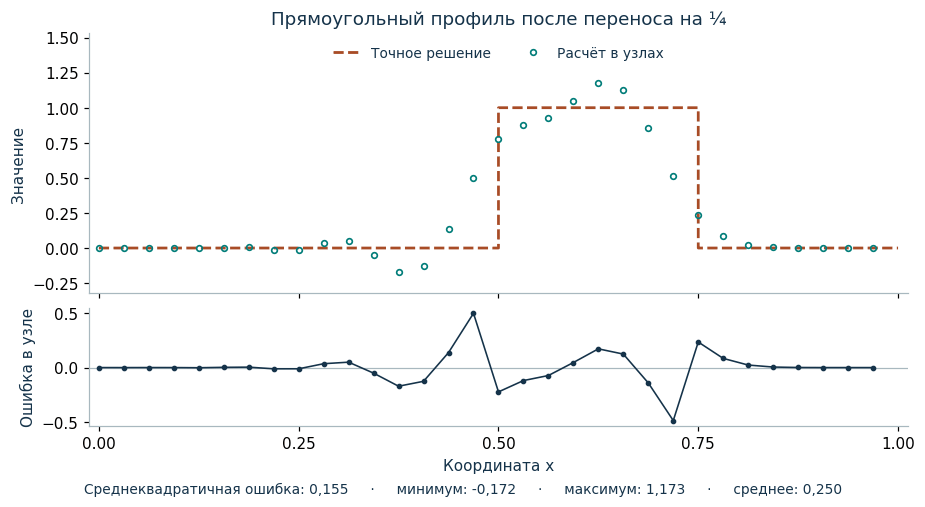

In [1]:
import numpy as np
import matplotlib.pyplot as plt

try:
    import ipywidgets as w
    from IPython.display import clear_output, display, Image
    from io import BytesIO
except ImportError:
    w = None

INK, TEAL, RUST = "#15334A", "#007C78", "#A84C26"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False,
                     "axes.edgecolor": "#A8B8BF", "axes.labelcolor": INK,
                     "text.color": INK, "font.size": 10, "axes.titlesize": 12,
                     "figure.facecolor": "white", "savefig.facecolor": "white"})


def experiment(figure, choices):
    defaults = {key: spec[-1] for key, spec in choices.items()}
    if w is None:
        figure(**defaults)
        plt.show()
        return
    controls = {}
    for key, (label, options, value) in choices.items():
        if isinstance(options, range):
            control = w.IntSlider(min=options.start, max=options[-1], value=value,
                                  step=options.step, continuous_update=False)
        else:
            control = w.Dropdown(options=options, value=value)
        control.description = label
        control.style.description_width = "initial"
        control.layout = w.Layout(width="310px", max_width="100%")
        controls[key] = control
    output = w.Output()

    def draw(change=None):
        fig = figure(**{key: control.value for key, control in controls.items()})
        with BytesIO() as buffer:
            fig.savefig(buffer, format="png", dpi=110, bbox_inches="tight", pad_inches=.1)
            img = Image(data=buffer.getvalue(), width=850)
        plt.close(fig)
        with output:
            clear_output(wait=True)
            display(img)

    for control in controls.values():
        control.observe(draw, names="value")
    layout = w.Layout(display="flex", flex_flow="row wrap")
    display(w.VBox([w.Box(list(controls.values()), layout=layout), output]))
    draw()


def lw_profile(x, profile):
    x = np.asarray(x) % 1
    if profile == "smooth":
        return np.cos(2*np.pi*x) + 0.25*np.sin(4*np.pi*x)
    if profile == "rectangle":
        return ((x >= 0.25) & (x < 0.5)).astype(float)
    raise ValueError(profile)


def lw_solution(profile="smooth", N=32, C=0.5):
    """Периодический перенос при c=1 до T=1/4. Возвращает x, точное и численное решения."""
    x = np.arange(N) / N
    steps = round(N / (4*C))
    if not np.isclose(steps*C/N, 0.25):
        raise ValueError("Требуется целое число шагов до T=1/4.")
    u = lw_profile(x, profile)
    for _ in range(steps):
        u = (C*(C+1)/2 * np.roll(u, 1) + (1-C*C)*u
             + C*(C-1)/2 * np.roll(u, -1))
    return x, lw_profile(x-0.25, profile), u


def lw_error(N, C=0.5, profile="smooth"):
    _, exact, computed = lw_solution(profile, N, C)
    return np.sqrt(np.mean((computed - exact)**2))


def lw_figure(profile="smooth", N=32, C=0.5):
    x, exact, computed = lw_solution(profile, N, C)
    grid = np.linspace(0, 1, 1025)
    diff = computed - exact
    norm = np.sqrt(np.mean(diff**2))
    fig, (top, bottom) = plt.subplots(2, 1, sharex=True, figsize=(8.3, 4.5),
                                      gridspec_kw={"height_ratios": [2.2, 1]},
                                      constrained_layout=True)
    style = "steps-post" if profile == "rectangle" else "default"
    top.plot(grid, lw_profile(grid-0.25, profile), "--", color="#A84C26",
             drawstyle=style, lw=1.8, label="Точное решение")
    top.plot(x, computed, "o", ms=3.7, markerfacecolor="none", color="#007C78",
             mew=1.1, label="Расчёт в узлах")
    top.legend(frameon=False, loc="upper center", ncol=2, fontsize=9)
    title = "Прямоугольный профиль" if profile == "rectangle" else "Сумма двух гармоник"
    top.set(title=title + " после переноса на ¼", ylabel="Значение",
            ylim=(-0.32, 1.53) if profile == "rectangle" else (-1.25, 1.57))
    bottom.axhline(0, color="#A8B8BF", lw=.8)
    bottom.plot(x, diff, "-o", color="#15334A", lw=1.05, ms=2.7)
    if np.max(np.abs(diff)) < 1e-14:
        bottom.set(ylim=(-.05, .05), yticks=[0])
    bottom.set(xlim=(-.012, 1.012), xticks=np.arange(5)/4,
               ylabel="Ошибка в узле", xlabel="Координата x")
    info = f"Среднеквадратичная ошибка: {norm:.3g}"
    if profile == "rectangle":
        info += (f"     ·     минимум: {min(computed):.3f}     ·     максимум: {max(computed):.3f}"
                 f"     ·     среднее: {np.mean(computed):.3f}")
    fig.supxlabel(info.replace(".", ","), fontsize=9)
    return fig


experiment(lw_figure, {
    "profile": ("Профиль", [("Сумма гармоник", "smooth"), ("Прямоугольник", "rectangle")], "rectangle"),
    "N": ("Число узлов", [16, 32, 64, 128], 32),
    "C": ("Число Куранта", [("1/2", 0.5), ("1", 1.0)], 0.5),
})

### Аппроксимация и устойчивость

Обозначим один шаг схемы через $B$. Подстановка точного слоя $\mathbf u^s$ даёт нормированную невязку $\boldsymbol\eta^s=(\mathbf u^{s+1}-B\mathbf u^s)/\tau$. При фиксированном $C$ первые несовпадающие члены в разложениях точного и численного шагов пропорциональны третьей производной. У точного сдвига это $-(c\tau)^3u_{xxx}/6$, у схемы — $-c\tau h^2u_{xxx}/6$. После вычитания и деления на $\tau$ получаем
$$
\eta_k^s=\frac{c(1-C^2)}{6}\,h^2 u_{xxx}(x_k,t_s)+O(h^3).
$$

Для проверки устойчивости достаточно подставить в схему гармонику $\exp(ik\theta)$, где $\theta=2\pi n/N$. Соседние значения отличаются от центрального множителями $\exp(\pm i\theta)$. Поэтому за шаг вся гармоника умножается на число
$$
G(\theta)=1-i C\sin\theta+C^2(\cos\theta-1).
$$
Насколько может увеличиться её амплитуда? Сумма квадратов вещественной и мнимой частей даёт
$$
|G(\theta)|^2=1-4C^2(1-C^2)\sin^4(\theta/2).
$$
При $0<C\le1$ все модули не превышают единицу. Это даёт устойчивость в среднеквадратичной норме с $K_T=1$. Для гладкого решения оценка Лакса при точном начальном слое принимает вид
$$
E_N\le T\max_{0\le s<M}\|\boldsymbol\eta^s\|_h=O(h^2).
$$

### Что видно при измельчении сетки?

При $C=1/2$ для гладкого профиля ожидается уменьшение ошибки примерно вчетверо при удвоении $N$. Этому соответствует наблюдаемый порядок $p=\log_2(E_N/E_{2N})$, близкий к двум. Рядом показана ошибка для прямоугольника на тех же сетках.

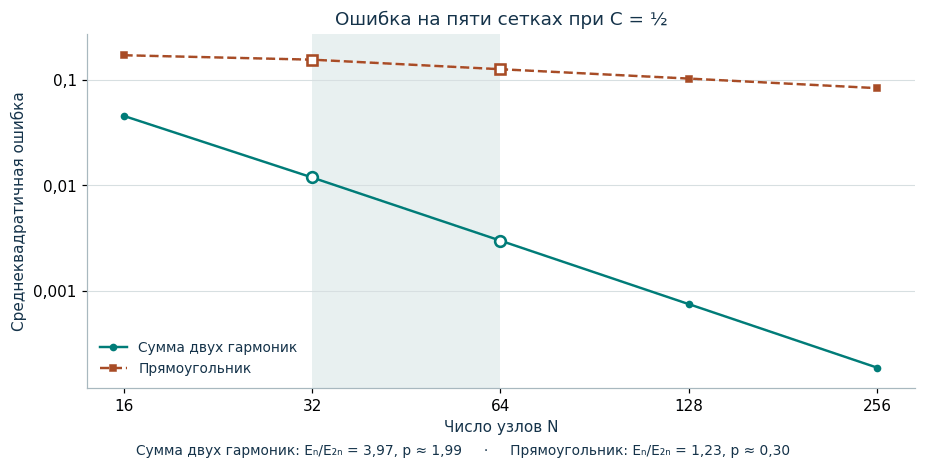

In [2]:
def lw_order_figure(rough_N=32):
    grids = np.array([16, 32, 64, 128, 256])
    start = list(grids[:-1]).index(rough_N)
    fig, ax = plt.subplots(figsize=(8.3, 4.15), constrained_layout=True)
    ax.axvspan(rough_N, 2*rough_N, color="#DCE8E9", alpha=.65, lw=0)
    foot = []
    for profile, label, color, style, marker in (
        ("smooth", "Сумма двух гармоник", "#007C78", "-", "o"),
        ("rectangle", "Прямоугольник", "#A84C26", "--", "s"),
    ):
        errors = np.array([lw_error(int(n), 0.5, profile) for n in grids])
        ax.plot(grids, errors, ls=style, marker=marker, ms=4, lw=1.6,
                label=label, color=color)
        pair = slice(start, start+2)
        ax.plot(grids[pair], errors[pair], ls="none", marker=marker,
                mfc="white", mec=color, mew=1.7, ms=7)
        ratio = errors[start] / errors[start+1]
        foot.append(f"{label}: Eₙ/E₂ₙ = {ratio:.2f}, p ≈ {np.log2(ratio):.2f}")
    ax.set_xscale("log", base=2)
    ax.set_yscale("log")
    ax.set_xticks(grids, [str(n) for n in grids])
    ax.set_yticks([1e-3, 1e-2, 1e-1], ["0,001", "0,01", "0,1"])
    ax.tick_params(axis="y", which="minor", left=False)
    ax.set(title="Ошибка на пяти сетках при C = ½", ylabel="Среднеквадратичная ошибка",
           xlabel="Число узлов N", xlim=(14, 294), ylim=(1.2e-4, .27))
    ax.grid(axis="y", color="#D7DFE1", lw=.7)
    ax.legend(loc="lower left", frameon=False, fontsize=9)
    fig.supxlabel("     ·     ".join(foot).replace(".", ","), fontsize=9)
    return fig


experiment(lw_order_figure, {"rough_N": ("Первая сетка, N", [16, 32, 64, 128], 32)})

У прямоугольного профиля нет третьей производной на скачке. Поэтому оценка через $u_{xxx}$ применима к гладкой кривой, а темп уменьшения ошибки на прямоугольнике приходится исследовать отдельно.

Откуда берутся выбросы возле скачка? При $C=1/2$ формула одного шага имеет вид
$$
U_k^{s+1}=\tfrac38 U_{k-1}^s+\tfrac34 U_k^s-\tfrac18 U_{k+1}^s.
$$
Слева от поднимающейся ступеньки три исходных значения равны $(0,0,1)$. После одного шага в центральном узле получается $-1/8$. У противоположного края набор $(1,1,0)$ даёт $9/8$. При этом среднее по всей сетке сохраняется точно в арифметике без округления. Действительно, периодический сдвиг сохраняет сумму значений, а три коэффициента в формуле в сумме дают единицу. Так один профиль позволяет проверить по отдельности сохранение среднего, сохранение диапазона значений и сходимость в выбранной норме.

## 2. Диффузия. Почему одна схема показывает два порядка точности?

Для уравнения $u_t=u_{xx}$ возьмём начальный профиль $\cos(2\pi x)$. Точное решение $u(x,t)=e^{-4\pi^2t}\cos(2\pi x)$ сохраняет форму и постепенно затухает. Явная разностная схема имеет вид
$$
U_k^{s+1}=rU_{k-1}^s+(1-2r)U_k^s+rU_{k+1}^s,\qquad r=\frac{\tau}{h^2}.
$$

Сравним два семейства сеток с шагами $\tau=h^2/4$ и $\tau=h^2/6$. При обоих значениях $r$ следующий слой получается взвешенным средним трёх соседних значений. Периодический сдвиг сохраняет норму, веса неотрицательны и в сумме равны единице. Поэтому для обеих последовательностей сеток $K_T=1$.

Чтобы узнать порядок сходимости, подставим точное решение. У производной по времени первая поправка равна $(\tau/2)u_{tt}$. У второй разности по пространству первая поправка равна $(h^2/12)u_{xxxx}$. По уравнению диффузии $u_{tt}=u_{xxxx}$. Вычитание пространственной разности из временной даёт при постоянном $r$
$$
\eta_k^s=\left(\frac{\tau}{2}-\frac{h^2}{12}\right)u_{xxxx}(x_k,t_s)+O(h^4)
=h^2\left(\frac r2-\frac1{12}\right)u_{xxxx}(x_k,t_s)+O(h^4).
$$

При $r=1/4$ первое слагаемое сохраняется. При **$r=1/6$** его коэффициент в точности равен нулю. Для достаточно гладкого решения невязка вдоль этого семейства сеток имеет порядок $O(h^4)$. Благодаря устойчивости ту же оценку получает глобальная ошибка при точном начальном слое. Сама временная разность по-прежнему имеет первый порядок по $\tau$ при раздельном анализе переменных.

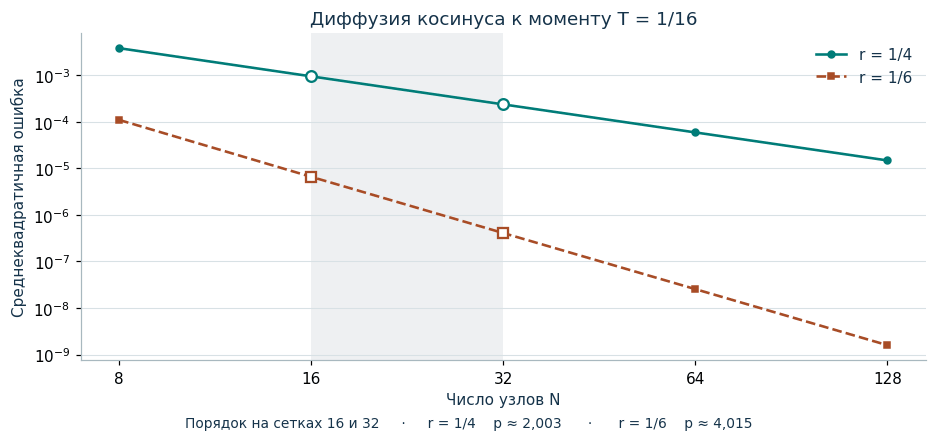

In [3]:
def heat_error(N, r):
    """Среднеквадратичная ошибка явной схемы в момент T = 1/16."""
    h, T = 1 / N, 1 / 16
    x = np.arange(N) * h
    initial = np.cos(2 * np.pi * x)
    U = initial.copy()
    M = round(T / (r * h**2))
    for _ in range(M):
        U = U + r * (np.roll(U, 1) - 2 * U + np.roll(U, -1))
    exact = np.exp(-4 * np.pi**2 * T) * initial
    return float(np.sqrt(np.mean((U - exact)**2)))


heat_grids = np.array([8, 16, 32, 64, 128])
heat_errors = {
    r: np.array([heat_error(N, r) for N in heat_grids])
    for r in (1/4, 1/6)
}


def heat_figure(rough_N=16):
    """Глобальная ошибка и наблюдаемый порядок на выбранной паре сеток."""
    j = list(heat_grids).index(rough_N)
    fine_N = heat_grids[j + 1]
    fig, ax = plt.subplots(figsize=(8.4, 3.9), constrained_layout=True)
    ax.axvspan(rough_N, fine_N, color="#15334A", alpha=.07, lw=0)
    summary = []
    for r, name, marker, style, color in (
        (1/4, "1/4", "o", "-", "#007C78"),
        (1/6, "1/6", "s", "--", "#A84C26"),
    ):
        err = heat_errors[r]
        ax.loglog(heat_grids, err, color=color, marker=marker, ls=style, lw=1.7,
                  ms=4.5, label=f"r = {name}")
        ax.plot([rough_N, fine_N], err[j:j+2], ls="none", marker=marker,
                mec=color, mfc="white", mew=1.5, ms=7)
        order = np.log2(err[j] / err[j+1])
        summary.append(f"r = {name}    p ≈ {order:.3f}".replace(".", ","))
    ax.set(xticks=heat_grids, xticklabels=[str(n) for n in heat_grids],
           xlabel="Число узлов N", ylabel="Среднеквадратичная ошибка",
           title="Диффузия косинуса к моменту T = 1/16")
    ax.minorticks_off()
    ax.grid(axis="y", color="#D8E1E5", lw=.7)
    ax.legend(frameon=False)
    fig.supxlabel(f"Порядок на сетках {rough_N} и {fine_N}     ·     " +
                  "      ·      ".join(summary), fontsize=9)
    return fig


experiment(heat_figure, {"rough_N": ("Первая сетка, N", [8, 16, 32, 64], 16)})

Все ошибки на рисунке вычислены в момент $T=1/16$. На сетках из 16 и 32 узлов наблюдаемый порядок равен примерно $2{,}003$ для $r=1/4$ и $4{,}015$ для $r=1/6$. Поэтому при сообщении наблюдаемого порядка существенно указать, как именно менялись **оба** шага.

## 3. Рабочая схема анализа

| Вопрос о новой схеме | Что позволяет на него ответить |
|---|---|
| С чем сравнивается результат? | Уравнение, начальные и граничные условия, точное решение или проверяемый эталон, норма ошибки и фиксированное время $T$. |
| Какую ошибку вносит один шаг? | Подстановка точного слоя в $B$. Разность с точным следующим слоем даёт дефект $d$. Для порядка аппроксимации исследуется $\eta=d/\tau$. |
| Что происходит с уже внесённым возмущением? | Оценка усиления за все шаги до $T$, единая для выбранного семейства сеток. Для периодических схем с постоянными коэффициентами её можно получить по гармоникам. |
| Какой порядок следует из анализа? | Для линейной схемы корректно поставленной линейной задачи аппроксимация и устойчивость дают сходимость. Скорость задают невязка и начальная ошибка с учётом гладкости решения и связи между $h$ и $\tau$. |
| Что подтверждает расчёт? | Несколько сеток при одном $T$, значения $E_N$ и отношений $E_N/E_{2N}$. Отдельно видны свойства, существенные для задачи, например сохранение среднего и диапазона значений или передача амплитуды и фазы. |